## MUltiple Linear Regression

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [4]:
df = pd.read_csv(r'D:\Practice\Linear_regression\Mulitple_LR\Student_Performance.csv')
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [5]:
df.shape

(10000, 6)

In [6]:
df1 = df.drop_duplicates()

In [7]:
df1['Extracurricular Activities'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [8]:
le = LabelEncoder()
df1['Extracurricular Activities'] = le.fit_transform(df1['Extracurricular Activities'])

In [9]:
df1.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [10]:
df1.info()

<class 'pandas.DataFrame'>
Index: 9873 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9873 non-null   int64  
 1   Previous Scores                   9873 non-null   int64  
 2   Extracurricular Activities        9873 non-null   int64  
 3   Sleep Hours                       9873 non-null   int64  
 4   Sample Question Papers Practiced  9873 non-null   int64  
 5   Performance Index                 9873 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 539.9 KB


In [11]:
X = df1.iloc[:,:-1]
y = df1['Performance Index']

<Axes: >

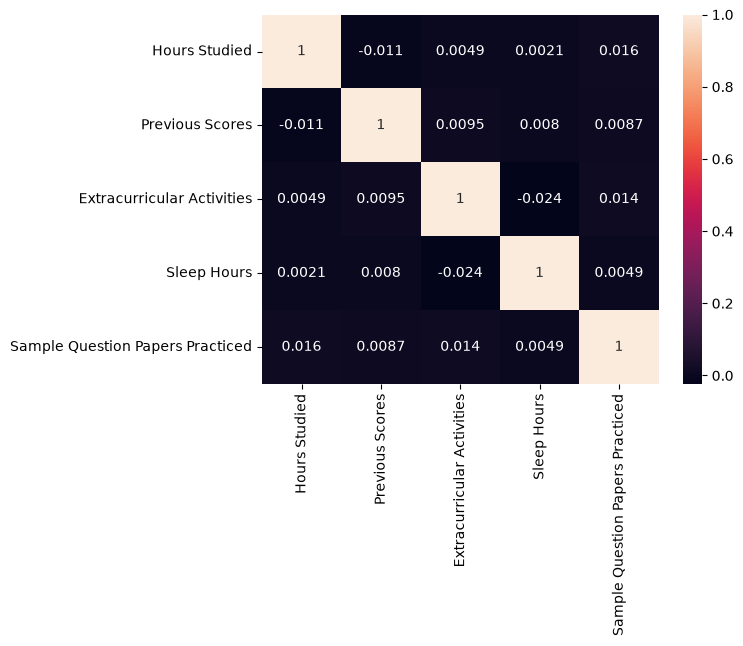

In [13]:
X.corr(numeric_only=True)
sns.heatmap(data= X.corr(numeric_only=True),annot=True)

In [14]:
vif = pd.DataFrame()

vif["Feature"] = X.columns

vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

                            Feature        VIF
0                     Hours Studied   4.265115
1                   Previous Scores  10.119579
2        Extracurricular Activities   1.929446
3                       Sleep Hours   9.843302
4  Sample Question Papers Practiced   3.350801


In [76]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("X_train Shape:",X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (7898, 5)
X_test Shape: (1975, 5)
y_train Shape: (7898,)
y_test Shape: (1975,)


In [77]:
model = LinearRegression()

In [78]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [79]:
y_pred = model.predict(X_test)

In [80]:
predicted = pd.DataFrame({
    "Y Actual ": y_test,
    "Y Predicted" : y_pred
})

print(predicted)

      Y Actual   Y Predicted
6099       47.0    46.480013
106        76.0    80.285379
9265       62.0    61.065188
4707       23.0    22.706315
2155       76.0    74.836868
...         ...          ...
8732       19.0    18.277835
3112       39.0    40.310084
5297       77.0    77.084436
6116       88.0    86.246766
5088       34.0    35.879338

[1975 rows x 2 columns]


In [81]:
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MSE: 4.305900938538477
MAE: 1.6469703984255568
R²: 0.9884301209927054
